# Basic Term Embedding  

1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences

2. Create simple example training data

In [2]:
# define documents
corpus = [
    'Well done!',
		'Good work',
		'Great effort',
		'nice work',
		'Excellent!',
		'Weak',
		'Poor effort!',
		'not good',
		'poor work',
		'Could have done better.'
]

# define class labels: 1 for positive sentiment, 0 for negative
labels = np.array([1,1,1,1,1,0,0,0,0,0])

3. One-hot encode vocabulary

In [3]:
# integer encode the documents
vocab_size = 50 # arbitrary int > # of unique words
encoded_docs = [one_hot(doc, vocab_size) for doc in corpus]
encoded_docs

[[46, 36],
 [25, 6],
 [27, 11],
 [30, 6],
 [45],
 [18],
 [22, 11],
 [9, 25],
 [22, 6],
 [39, 40, 36, 24]]

4. Pad documents to same length for fixed-width embedding layer input

In [4]:
# pad documents to a max length of 4 words
max_length = 4 # REQUIRES STUDENT INPUT
padded_docs = pad_sequences(encoded_docs, maxlen=max_length, padding='post')
padded_docs

array([[46, 36,  0,  0],
       [25,  6,  0,  0],
       [27, 11,  0,  0],
       [30,  6,  0,  0],
       [45,  0,  0,  0],
       [18,  0,  0,  0],
       [22, 11,  0,  0],
       [ 9, 25,  0,  0],
       [22,  6,  0,  0],
       [39, 40, 36, 24]], dtype=int32)

5. Build, compile, and inspect simple embedding model

In [5]:
# define the model
inputs = Input(shape=(max_length,))
x = Embedding(input_dim=vocab_size, output_dim=8)(inputs) # REQUIRES STUDENT INPUT
x = Flatten()(x)
x2d = Dense(2, activation='linear', name='dense_2d')(x) # REQUIRES STUDENT INPUT
outputs = Dense(1, activation='sigmoid')(x2d)

model = Model(inputs=inputs, outputs=outputs)

# compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# summarize the model
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 4, 8)           │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2d (Dense)                │ (None, 2)              │            66 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469 (1.83 KB)

 Trainable params: 469 (1.83 KB)

 Non-trainable params: 0 (0.00 B)

6. Train model

In [6]:
# train
_ = model.fit(padded_docs, labels, epochs=30, verbose=1) # REQUIRES STUDENT INPUT

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6924
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6000 - loss: 0.6914
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7000 - loss: 0.6903
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7000 - loss: 0.6892
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7000 - loss: 0.6882
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7000 - loss: 0.6871
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9000 - loss: 0.6860
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9000 - loss: 0.6849
Epoch 9/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9000 - loss: 0.6839
Epoch 10/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9000 - loss: 0.6828
Epoch 11/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9000 - loss: 0.6817
Epoch 12/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9000 - loss: 0.6806
Epo

7. View predictions

In [7]:
# view predictions
model.predict(padded_docs) # REQUIRES STUDENT INPUT

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


array([[0.51851135],
       [0.5189488 ],
       [0.5143666 ],
       [0.52114576],
       [0.5198801 ],
       [0.4889121 ],
       [0.4855062 ],
       [0.48236352],
       [0.49719077],
       [0.45753902]], dtype=float32)

8. Assess accuracy

In [8]:
# evaluate the model
loss, accuracy = model.evaluate(padded_docs, labels, verbose=0)
print('Accuracy: %f' % (accuracy*100))

Accuracy: 100.000000


9. Extract "deep" features for plotting
* These are the term embeddings!

In [9]:
# Extract features from the 2D layer
feature_model = Model(inputs=model.input, outputs=model.get_layer('dense_2d').output) # REQUIRES STUDENT INPUT
features = feature_model.predict(padded_docs)
features

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


array([[ 0.10946044, -0.00642963],
       [ 0.11716153, -0.04365714],
       [ 0.09351271, -0.0441594 ],
       [ 0.12531494, -0.02156513],
       [ 0.11784492, -0.01530448],
       [-0.04327991, -0.00901227],
       [-0.05467453, -0.05167642],
       [-0.06985099, -0.05915487],
       [ 0.0065604 , -0.05709183],
       [-0.19181257, -0.10643681]], dtype=float32)

10. Plot the features

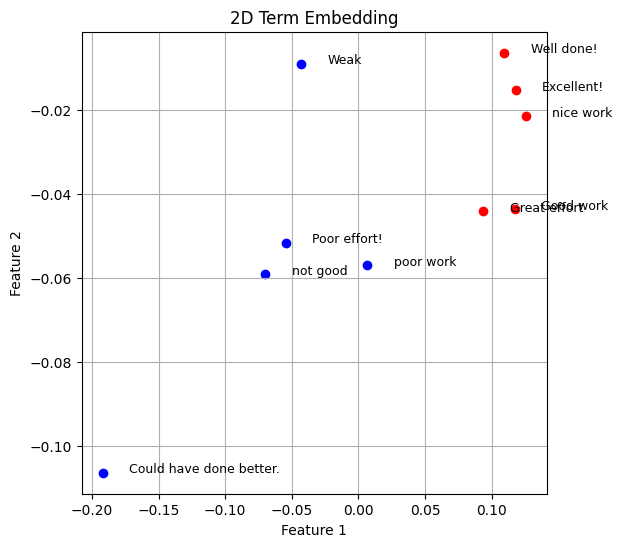

In [10]:
# Plot the features
plt.figure(figsize=(6, 6))
for i, label in enumerate(labels):
    color = 'blue' if label == 0 else 'red'
    plt.scatter(features[i, 0], features[i, 1], c=color, label=f"Class {label}" if i == 0 or i == 1 else "")
    plt.text(features[i, 0] + 0.02, features[i, 1], corpus[i], fontsize=9)
plt.title("2D Term Embedding")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()